In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

In [4]:
df = pd.read_csv('data_to_be_cleaned_v2.csv')

In [7]:
df['date'] =pd.to_datetime(df['date'],format = '%Y-%m-%d')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    50 non-null     datetime64[ns]
 1   sales   41 non-null     float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 932.0 bytes


In [24]:
na_dates = df[df["sales"].isna()]["date"].values;print(na_dates)

['2024-01-16T00:00:00.000000000' '2024-01-25T00:00:00.000000000'
 '2024-01-29T00:00:00.000000000' '2024-02-05T00:00:00.000000000'
 '2024-02-06T00:00:00.000000000' '2024-02-07T00:00:00.000000000'
 '2024-02-08T00:00:00.000000000' '2024-02-09T00:00:00.000000000'
 '2024-02-10T00:00:00.000000000']


In [50]:
df['linear_interp'] = df['sales'].interpolate(method='linear')
df['quadratic_interp'] = df['sales'].interpolate(method='cubicspline')

In [51]:
df

,date,sales,linear_interp,quadratic_interp
0,2024-01-01,0.000000,0.000000,0.000000
1,2024-01-02,0.011865,0.011865,0.011865
2,2024-01-03,0.070769,0.070769,0.070769
3,2024-01-04,0.769379,0.769379,0.769379
4,2024-01-05,1.475500,1.475500,1.475500
5,2024-01-06,2.082050,2.082050,2.082050
6,2024-01-07,1.530587,1.530587,1.530587
7,2024-01-08,3.475500,3.475500,3.475500
8,2024-01-09,4.171263,4.171263,4.171263
9,2024-01-10,5.957488,5.957488,5.957488


<Figure size 1200x500 with 0 Axes>

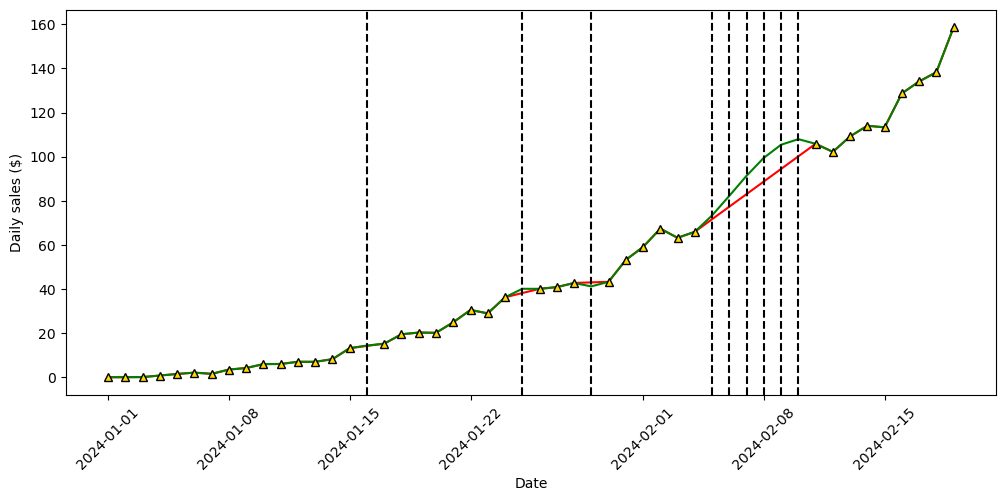

In [52]:
plt.figure(figsize=(12,5))
plt.figure(figsize=(12,5))
plt.plot(df['date'],df["linear_interp"],'-',label="sales",color='red',markeredgewidth=1,markeredgecolor='black')
plt.plot(df['date'],df["quadratic_interp"],'-',label="sales",color='green',markeredgewidth=1,markeredgecolor='black')
plt.plot(df['date'],df["sales"],'^',label="sales",color='gold',markeredgewidth=1,markeredgecolor='black')
for date in na_dates:
    plt.axvline(date,linestyle='dashed',color='black')
plt.xticks(rotation=45)
plt.xlabel('Date')
plt.ylabel('Daily sales ($)')
plt.show()

In [53]:
errors_df = df[['date','sales']].copy() 

In [61]:
errors_df['dummy_sales'] = errors_df["sales"]

In [62]:
errors_df.loc[(1+errors_df.index)%5 == 0 ,"dummy_sales"] = np.nan

In [64]:
for m in ['linear','quadratic','cubicspline']:
    errors_df[f'{m}_interpolation'] = errors_df['dummy_sales'].interpolate(method=m)

In [65]:
errors_df

,date,sales,dummy_sales,linear_interpolation,quadratic_interpolation,cubicspline_interpolation
0,2024-01-01,0.000000,0.000000,0.000000,0.000000,0.000000
1,2024-01-02,0.011865,0.011865,0.011865,0.011865,0.011865
2,2024-01-03,0.070769,0.070769,0.070769,0.070769,0.070769
3,2024-01-04,0.769379,0.769379,0.769379,0.769379,0.769379
4,2024-01-05,1.475500,NaN,1.425714,1.762473,1.845916
5,2024-01-06,2.082050,2.082050,2.082050,2.082050,2.082050
6,2024-01-07,1.530587,1.530587,1.530587,1.530587,1.530587
7,2024-01-08,3.475500,3.475500,3.475500,3.475500,3.475500
8,2024-01-09,4.171263,4.171263,4.171263,4.171263,4.171263
9,2024-01-10,5.957488,NaN,5.085632,4.935806,4.853978


In [74]:
errors_df

,date,sales,dummy_sales,linear_interpolation,quadratic_interpolation,cubicspline_interpolation
0,2024-01-01,0.000000,0.000000,0.000000,0.000000,0.000000
1,2024-01-02,0.011865,0.011865,0.011865,0.011865,0.011865
2,2024-01-03,0.070769,0.070769,0.070769,0.070769,0.070769
3,2024-01-04,0.769379,0.769379,0.769379,0.769379,0.769379
4,2024-01-05,1.475500,NaN,1.425714,1.762473,1.845916
5,2024-01-06,2.082050,2.082050,2.082050,2.082050,2.082050
6,2024-01-07,1.530587,1.530587,1.530587,1.530587,1.530587
7,2024-01-08,3.475500,3.475500,3.475500,3.475500,3.475500
8,2024-01-09,4.171263,4.171263,4.171263,4.171263,4.171263
9,2024-01-10,5.957488,NaN,5.085632,4.935806,4.853978


In [73]:
(abs(errors_df['dummy_sales']-errors_df['linear_interpolation']))

0     0.0
1     0.0
2     0.0
3     0.0
4     NaN
5     0.0
6     0.0
7     0.0
8     0.0
9     NaN
10    0.0
11    0.0
12    0.0
13    0.0
14    NaN
15    NaN
16    0.0
17    0.0
18    0.0
19    NaN
20    0.0
21    0.0
22    0.0
23    0.0
24    NaN
25    0.0
26    0.0
27    0.0
28    NaN
29    NaN
30    0.0
31    0.0
32    0.0
33    0.0
34    NaN
35    NaN
36    NaN
37    NaN
38    NaN
39    NaN
40    NaN
41    0.0
42    0.0
43    0.0
44    NaN
45    0.0
46    0.0
47    0.0
48    0.0
49    NaN
dtype: float64

In [75]:
for i in range(3):
    print(f'{errors_df.columns[3+i]} gives MAE of {np.mean(abs(errors_df['sales']-errors_df[errors_df.columns[3+i]]))}')

linear_interpolation gives MAE of 0.932578694127738
quadratic_interpolation gives MAE of 0.5162308948169512
cubicspline_interpolation gives MAE of 0.5359692876998357
